# Clase 2: tablas dinámicas, visualización e interpretación de datos

**Duración:** 180 minutos (3 horas reloj)  
**Modalidad:** explicación, demostración, práctica guiada y desafío integrador  
**Herramientas:** Python, Pandas y Matplotlib  
**Dataset:** ventas de una librería escolar, incluido en el notebook

## Objetivos de aprendizaje

Al finalizar la clase, el estudiante será capaz de:

- construir tablas dinámicas mediante `pivot_table()`;
- elaborar tablas de frecuencias con `pd.crosstab()`;
- seleccionar gráficos adecuados para diferentes preguntas;
- crear y personalizar gráficos con Pandas y Matplotlib;
- interpretar tablas y gráficos sin confundir observaciones con opiniones;
- comunicar hallazgos mediante un miniinforme basado en datos.



## 1. Inicio: una decisión basada en datos 
La librería escolar ya corrigió errores y resumió sus ventas. Ahora la administración debe decidir:

> ¿Qué productos debería promocionar en cada sucursal y cómo podemos explicar la decisión de manera clara?

Una lista extensa de números puede ser correcta, pero difícil de interpretar. Las **tablas dinámicas** reorganizan los datos y los **gráficos** hacen visibles las comparaciones, proporciones y tendencias.

### Preguntas para conversar

1. ¿Es lo mismo registrar muchas operaciones que obtener mayor facturación?
2. ¿Qué resulta más fácil de comprender: 100 filas o un gráfico resumido?
3. ¿Un gráfico bonito siempre representa correctamente la información?

### Ruta del análisis

En la clase anterior llegamos hasta la agrupación. Hoy completaremos la comunicación de resultados:

1. Datos originales.
2. Limpieza.
3. Análisis exploratorio.
4. Agrupación y resumen.
5. Tablas comparativas.
6. Visualización.
7. Interpretación y decisiones.

In [2]:
# Importación de las herramientas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.style.use('seaborn-v0_8-whitegrid')

ModuleNotFoundError: No module named 'pandas'

### Dataset de continuidad

La siguiente celda genera y deja limpio el dataset utilizado en la clase anterior. Así todos podrán trabajar sin depender de archivos externos. Cada fila representa una operación de venta.

In [ ]:
rng = np.random.default_rng(2026)
n = 120
productos = np.array(['Cuaderno', 'Bolígrafo', 'Carpeta', 'Regla', 'Mochila', 'Calculadora'])
categorias = {
    'Cuaderno': 'Papelería', 'Bolígrafo': 'Papelería',
    'Carpeta': 'Papelería', 'Regla': 'Útiles',
    'Mochila': 'Accesorios', 'Calculadora': 'Tecnología'
}
precios = {
    'Cuaderno': 18000, 'Bolígrafo': 5000, 'Carpeta': 12000,
    'Regla': 7000, 'Mochila': 95000, 'Calculadora': 65000
}
producto = rng.choice(productos, size=n, p=[0.25, 0.23, 0.16, 0.12, 0.10, 0.14])
df_limpio = pd.DataFrame({
    'fecha': pd.to_datetime('2026-03-01') + pd.to_timedelta(rng.integers(0, 92, size=n), unit='D'),
    'producto': producto,
    'categoria': [categorias[p] for p in producto],
    'cantidad': rng.integers(1, 8, size=n),
    'precio_unitario': [precios[p] for p in producto],
    'sucursal': rng.choice(['Centro', 'Terminal', 'Mercado'], size=n),
    'vendedor': rng.choice(['Ana', 'Carlos', 'Lucía', 'Miguel'], size=n)
})
df_limpio['total_venta'] = df_limpio['cantidad'] * df_limpio['precio_unitario']
df_limpio['mes'] = df_limpio['fecha'].dt.month
df_limpio['nombre_mes'] = df_limpio['mes'].map({3: 'Marzo', 4: 'Abril', 5: 'Mayo'})
df_limpio.head()

### Activación de conocimientos previos

Antes de avanzar, responda usando Pandas:

1. ¿Cuántas filas y columnas tiene el dataset?
2. ¿Cuál es la facturación total?
3. ¿Qué sucursal tiene mayor facturación?
4. ¿Qué diferencia existe entre `groupby()` y un filtro?

In [ ]:
# Escriba aquí sus respuestas de recuperación
# ¿Cuántas filas y columnas tiene el dataset?

filas, columnas = df_limpio.shape

print("Filas:", filas)
print("Columnas:", columnas)

In [ ]:
#2. ¿Cuál es la facturación total?
facturacion_total = df_limpio["total_venta"].sum()

print("Facturación total:", facturacion_total)

In [ ]:
#3. ¿Qué sucursal tiene mayor facturación?
facturacion_sucursal = df_limpio.groupby("sucursal")["total_venta"].sum()

sucursal_mayor = facturacion_sucursal.idxmax()

print("Sucursal con mayor facturación:", sucursal_mayor)

4. ¿Qué diferencia existe entre `groupby()` y un filtro?

La diferencia es que groupby agrupa datos por columnas y luego permite realizar operaciones sobre esas columnas, mientras que un filtro es para seleccionar las filas que cumplen x condicion


## 2. Tablas dinámicas con `pivot_table()` 

### Concepto principal

Una **tabla dinámica** resume una gran cantidad de registros y permite compararlos mediante filas y columnas.

Su estructura básica es:

```python
pd.pivot_table(
    datos,
    values='columna_numerica',
    index='filas',
    columns='columnas',
    aggfunc='operacion',
    fill_value=0
)
```

| Parámetro | Función |
|---|---|
| `values` | Indica qué valores numéricos se resumirán |
| `index` | Define las categorías que aparecerán en las filas |
| `columns` | Define las categorías que aparecerán en las columnas |
| `aggfunc` | Establece la operación: suma, promedio, conteo, etc. |
| `fill_value` | Reemplaza combinaciones vacías, normalmente por cero |

### Ejemplo 1: facturación por sucursal y categoría

Pregunta: **¿Cuánto facturó cada categoría en cada sucursal?**

In [ ]:
tabla_sucursal_categoria = pd.pivot_table(
    df_limpio,
    values='total_venta',
    index='sucursal',
    columns='categoria',
    aggfunc='sum',
    fill_value=0
)
tabla_sucursal_categoria

### Cómo leer la tabla

- Una **fila** contiene los resultados de una sucursal.
- Una **columna** contiene los resultados de una categoría.
- Cada **celda** es la suma de `total_venta` de esa combinación.
- El cero indica que no hubo registros para la combinación.

No basta con mostrar la tabla: debemos convertir sus números en afirmaciones verificables.

### Ejemplo 2: unidades vendidas por producto y mes


In [ ]:
tabla_producto_mes = pd.pivot_table(
    df_limpio, values='cantidad', index='producto', columns='nombre_mes',
    aggfunc='sum', fill_value=0
).reindex(columns=['Marzo', 'Abril', 'Mayo'])
tabla_producto_mes

### Ejemplo 3: promedio y totales generales

`margins=True` agrega una fila y una columna de totales. Aquí calculamos el promedio de cada operación, no la suma.

In [ ]:
promedio_vendedor_sucursal = pd.pivot_table(
    df_limpio, values='total_venta', index='vendedor', columns='sucursal',
    aggfunc='mean', fill_value=0, margins=True, margins_name='Promedio general'
).round(2)
promedio_vendedor_sucursal

### Ejemplo 4: varias operaciones en una tabla

También podemos solicitar más de una función de resumen.

In [ ]:
tabla_multiple = pd.pivot_table(
    df_limpio, values='total_venta', index='categoria',
    aggfunc=['sum', 'mean', 'count']
).round(2)
tabla_multiple

### `groupby()` frente a `pivot_table()`

| Herramienta | Conviene usarla cuando... |
|---|---|
| `groupby()` | Necesitamos agrupar y producir una serie o tabla lineal |
| `pivot_table()` | Necesitamos comparar dos categorías en filas y columnas |

Ambas pueden obtener resultados equivalentes. La diferencia principal está en la forma de organizar la salida.

## 3. Práctica guiada 1 

Resuelva los siguientes ejercicios. Debajo de cada resultado escriba una oración interpretativa.

1. Cree una tabla con la **facturación total por vendedor y mes**.
2. Cree una tabla con las **unidades vendidas por sucursal y producto**.
3. Calcule el **promedio de venta por categoría y sucursal**.
4. Repita el ejercicio 1 incluyendo totales mediante `margins=True`.
5. Identifique, observando sus tablas, qué vendedor facturó más y qué combinación producto-sucursal vendió más unidades.

In [ ]:
# Ejercicio 1: facturación total por vendedor y mes
ventas_vendedor_mes = df_limpio.pivot_table(
    index="vendedor",
    columns="nombre_mes",
    values="total_venta",
    aggfunc="sum",
    fill_value=0
).reindex(columns=["Marzo", "Abril", "Mayo"])

ventas_vendedor_mes


In [ ]:
# Ejercicio 2: unidades vendidas por sucursal y producto
unidades_sucursal_producto = df_limpio.pivot_table(
    index="sucursal",
    columns="producto",
    values="cantidad",
    aggfunc="sum",
    fill_value=0
)

unidades_sucursal_producto

In [ ]:
# Ejercicio 3: promedio de venta por categoría y sucursal
promedio_categoria_sucursal = df_limpio.pivot_table(
    index="categoria",
    columns="sucursal",
    values="total_venta",
    aggfunc="mean",
    fill_value=0
).round(2)

display(promedio_categoria_sucursal)

# Ejercicio 4: facturación por vendedor y mes con totales
facturacion_con_totales = df_limpio.pivot_table(
    index="vendedor",
    columns="nombre_mes",
    values="total_venta",
    aggfunc="sum",
    fill_value=0,
    margins=True,
    margins_name="Total general"
).reindex(columns=["Marzo", "Abril", "Mayo", "Total general"])

display(facturacion_con_totales)

### Interpretación de la práctica

- **Ejercicio 1:** Miguel tuvo el mejor mes individual (Marzo, Gs. 2.005.000), mientras que Ana se destacó en Abril (Gs. 1.857.000) y Lucía en Mayo (Gs. 1.094.000): ningún vendedor lidera todos los meses.
- **Ejercicio 2:** Carpeta es el producto con más unidades en Centro (45) y en Mercado (50); en Terminal se vende menos en general, pero Carpeta también lidera allí (38).
- **Ejercicio 3:** el promedio por operación de Accesorios y Tecnología es muy superior al de Papelería y Útiles, porque se trata de productos de mayor precio unitario.
- **Ejercicio 4:** la fila de totales muestra que Marzo fue el mes de mayor facturación (Gs. 4.390.000) y Mayo el de menor (Gs. 3.256.000).
- **Hallazgo 1:** el vendedor que facturó más fue **Miguel**.
- **Hallazgo 2:** la combinación que más unidades vendió fue **Carpeta en Mercado**.
- **Evidencia numérica utilizada:** Miguel acumula **Gs. 3.547.000** (columna *Total general*), frente a Gs. 3.198.000 de Ana, el segundo. Carpeta en Mercado suma **50 unidades**, la celda más alta de la tabla sucursal × producto.

In [ ]:
total_por_vendedor = df_limpio.groupby("vendedor")["total_venta"].sum()
mejor_vendedor = total_por_vendedor.idxmax()

unidades_producto_sucursal = (
    df_limpio.groupby(["producto", "sucursal"])["cantidad"]
    .sum()
)

mejor_combinacion = unidades_producto_sucursal.idxmax()

print("Vendedor que más facturó:", mejor_vendedor)
print("Producto y sucursal con más unidades:", mejor_combinacion)

## 4. Tablas de frecuencia con `pd.crosstab()` 

Una **tabla de frecuencia cruzada** cuenta cuántas veces aparece cada combinación de dos variables categóricas.

Pregunta: **¿Cuántas operaciones registró cada vendedor en cada sucursal?**

In [ ]:
frecuencia_vendedor_sucursal = pd.crosstab(
    df_limpio['vendedor'],
    df_limpio['sucursal'],
    margins=True,
    margins_name='Total'
)
frecuencia_vendedor_sucursal

### Frecuencias porcentuales

Con `normalize='index'` cada fila suma 100 %. Esto ayuda a comparar distribuciones aunque los vendedores tengan distinta cantidad de operaciones.

In [ ]:
porcentaje_vendedor_sucursal = pd.crosstab(
    df_limpio['vendedor'], df_limpio['sucursal'], normalize='index'
) * 100
porcentaje_vendedor_sucursal.round(1)

### Diferencia fundamental

- `crosstab()` responde normalmente **cuántos registros existen**.
- `pivot_table()` responde normalmente **cuánto suman, promedian o representan los valores**.

Una persona puede aparecer en muchas operaciones pequeñas y, aun así, no ser quien más facturó.

### Práctica guiada 2

1. Construya una tabla de frecuencias entre `producto` y `sucursal`.
2. Agregue los totales.
3. Obtenga porcentajes por fila.
4. Explique por qué esta tabla no muestra directamente la facturación.

In [ ]:
# Resuelva aquí la práctica guiada 2
# 1. Construya una tabla de frecuencias entre `producto` y `sucursal`.
frecuencia_producto = pd.crosstab(
    index=df_limpio["producto"],
    columns=df_limpio["sucursal"]
)

frecuencia_producto

In [ ]:
#2. Agregue los totales.
frecuencia_con_total = pd.crosstab(
    df_limpio["producto"],
    df_limpio["sucursal"],
    margins=True,
    margins_name="Total"
)

frecuencia_con_total

In [ ]:
#3. Obtenga porcentajes por fila.
porcentaje_producto = (
    pd.crosstab(
        df_limpio["producto"],
        df_limpio["sucursal"],
        normalize="index"
    )
    .mul(100)
    .round(1)
)

porcentaje_producto

# 4. Explique por qué esta tabla no muestra directamente la facturación.
La tabla no muestra directamente la facturación porque crosstab() cuenta la cantidad de operaciones, pero no suma el valor de totalventa

## Pausa activa y revisión 

Antes de continuar, complete verbalmente:

1. Una tabla dinámica sirve para resumir y comparar datos organizándolos en filas y columnas.
2. El parámetro aggfunc sirve para indicar qué operación queremos realizar sobre los datos, como suma, promedio o conteo.
3. crosstab() es útil cuando necesitamos contar cuántas veces aparece cada combinación de categorías.
4. Contar operaciones no es igual que sumar facturación porque una operación puede tener un valor diferente a otra, por lo que tener más operaciones no significa necesariamente haber facturado más.

## 5. Visualización de datos 
### Elegir el gráfico correcto

| Pregunta | Gráfico recomendado |
|---|---|
| ¿Qué categoría vende más? | Barras |
| ¿Cómo cambia la venta con el tiempo? | Líneas |
| ¿Qué proporción representa cada categoría? | Circular, con pocas categorías |
| ¿Cómo se comparan categorías entre sucursales? | Barras agrupadas o apiladas |

Un buen gráfico debe tener título claro, nombres de ejes, unidades, escala legible y colores que no confundan.

### Ejemplo 1: gráfico de barras para comparar categorías


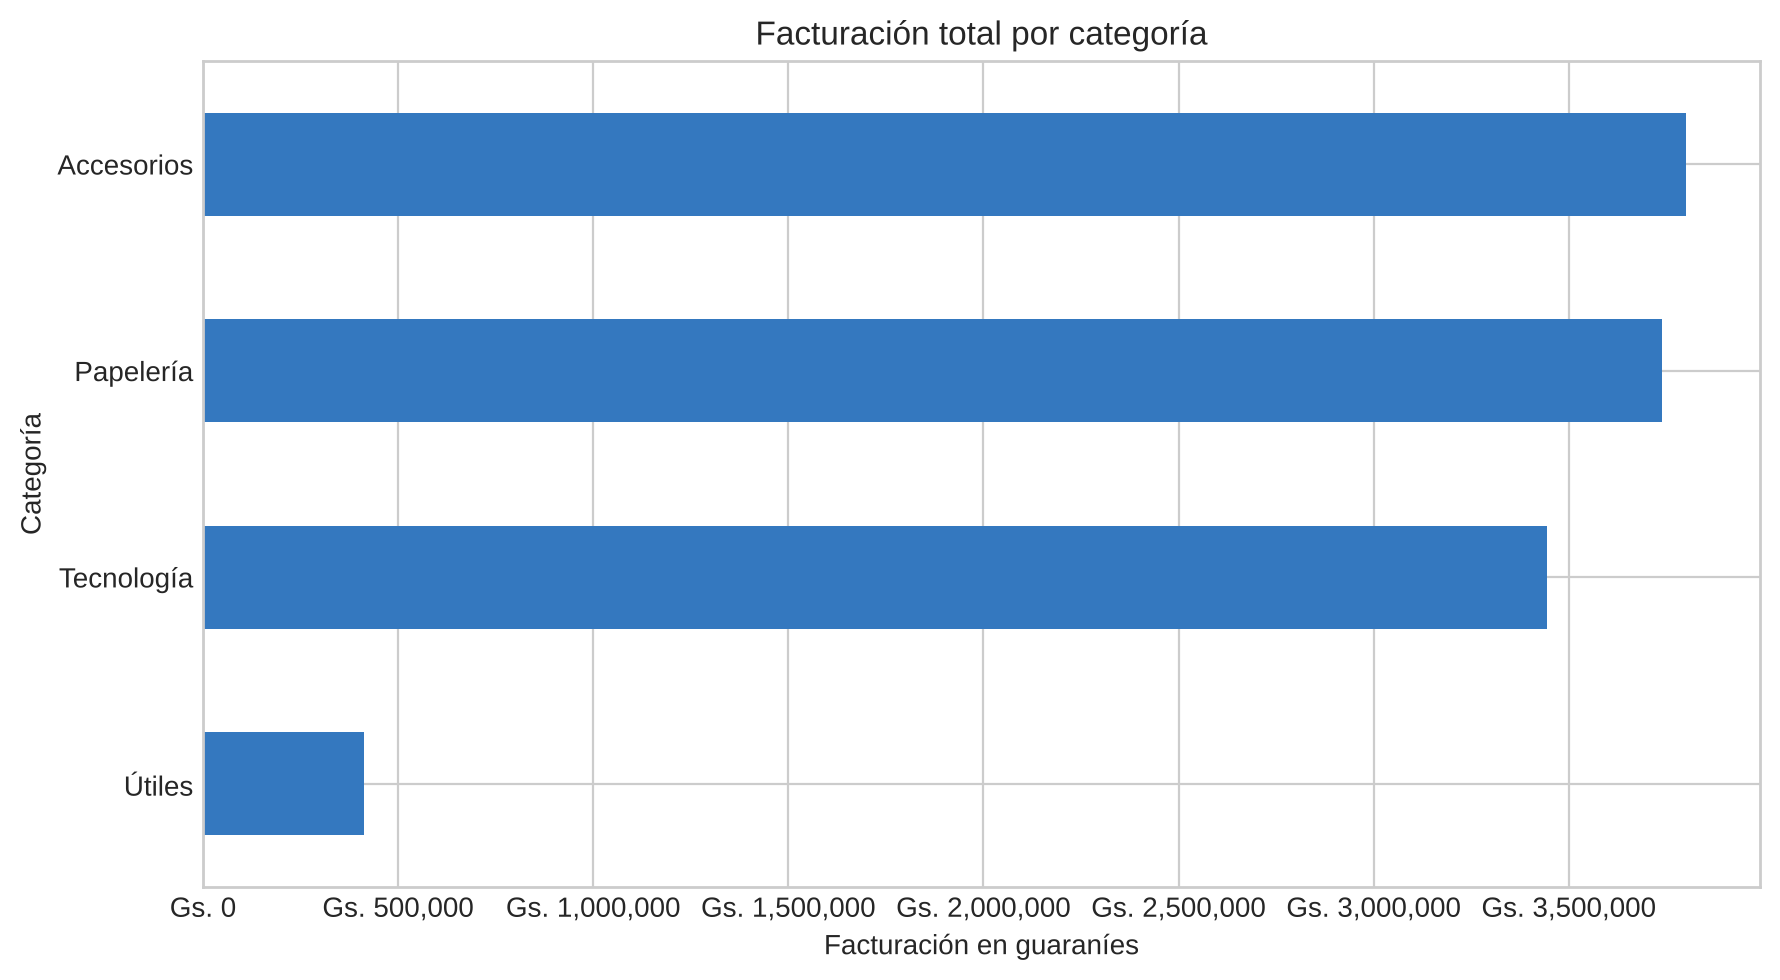

In [19]:
ventas_categoria = df_limpio.groupby('categoria')['total_venta'].sum().sort_values()
ax = ventas_categoria.plot(kind='barh', color='#3478BF', figsize=(9, 5))
ax.set_title('Facturación total por categoría')
ax.set_xlabel('Facturación en guaraníes')
ax.set_ylabel('Categoría')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'Gs. {x:,.0f}'))
plt.tight_layout()
plt.show()

### Ejemplo 2: gráfico de líneas para observar cambios

Para una secuencia temporal debemos respetar el orden cronológico.

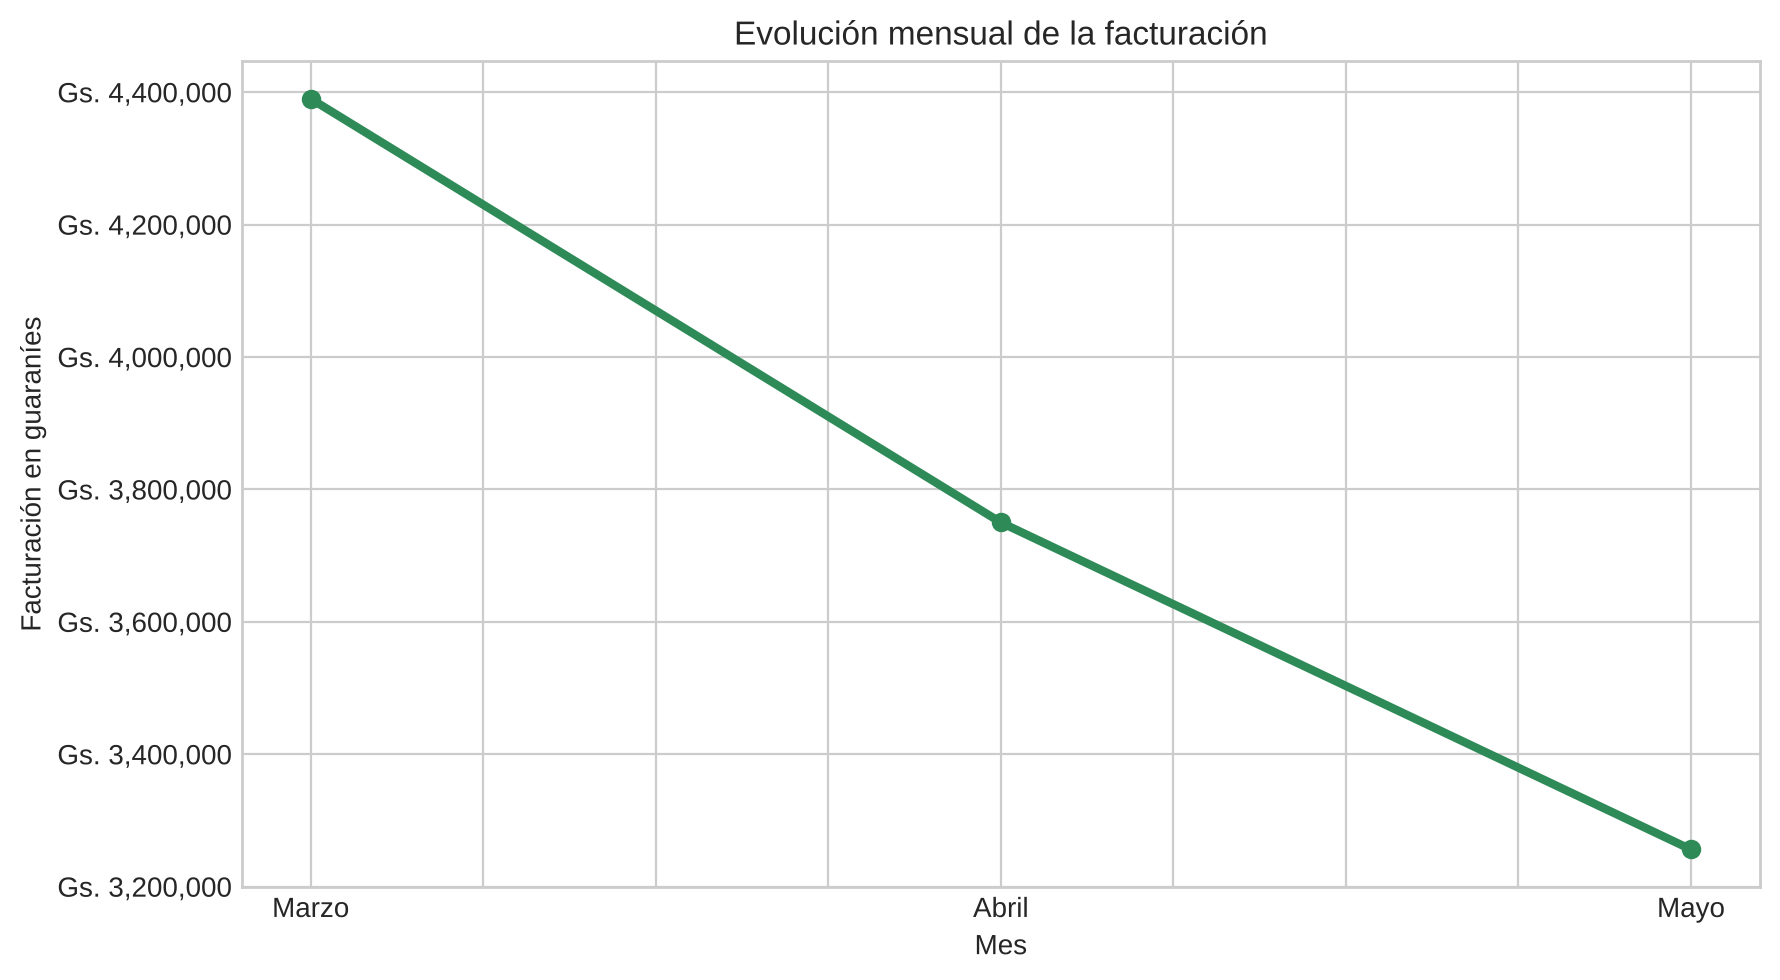

In [20]:
orden_meses = ['Marzo', 'Abril', 'Mayo']
ventas_mes = df_limpio.groupby('nombre_mes')['total_venta'].sum().reindex(orden_meses)
ax = ventas_mes.plot(kind='line', marker='o', linewidth=3, color='#2E8B57', figsize=(9, 5))
ax.set_title('Evolución mensual de la facturación')
ax.set_xlabel('Mes')
ax.set_ylabel('Facturación en guaraníes')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'Gs. {x:,.0f}'))
plt.tight_layout()
plt.show()

### Ejemplo 3: barras agrupadas a partir de una tabla dinámica


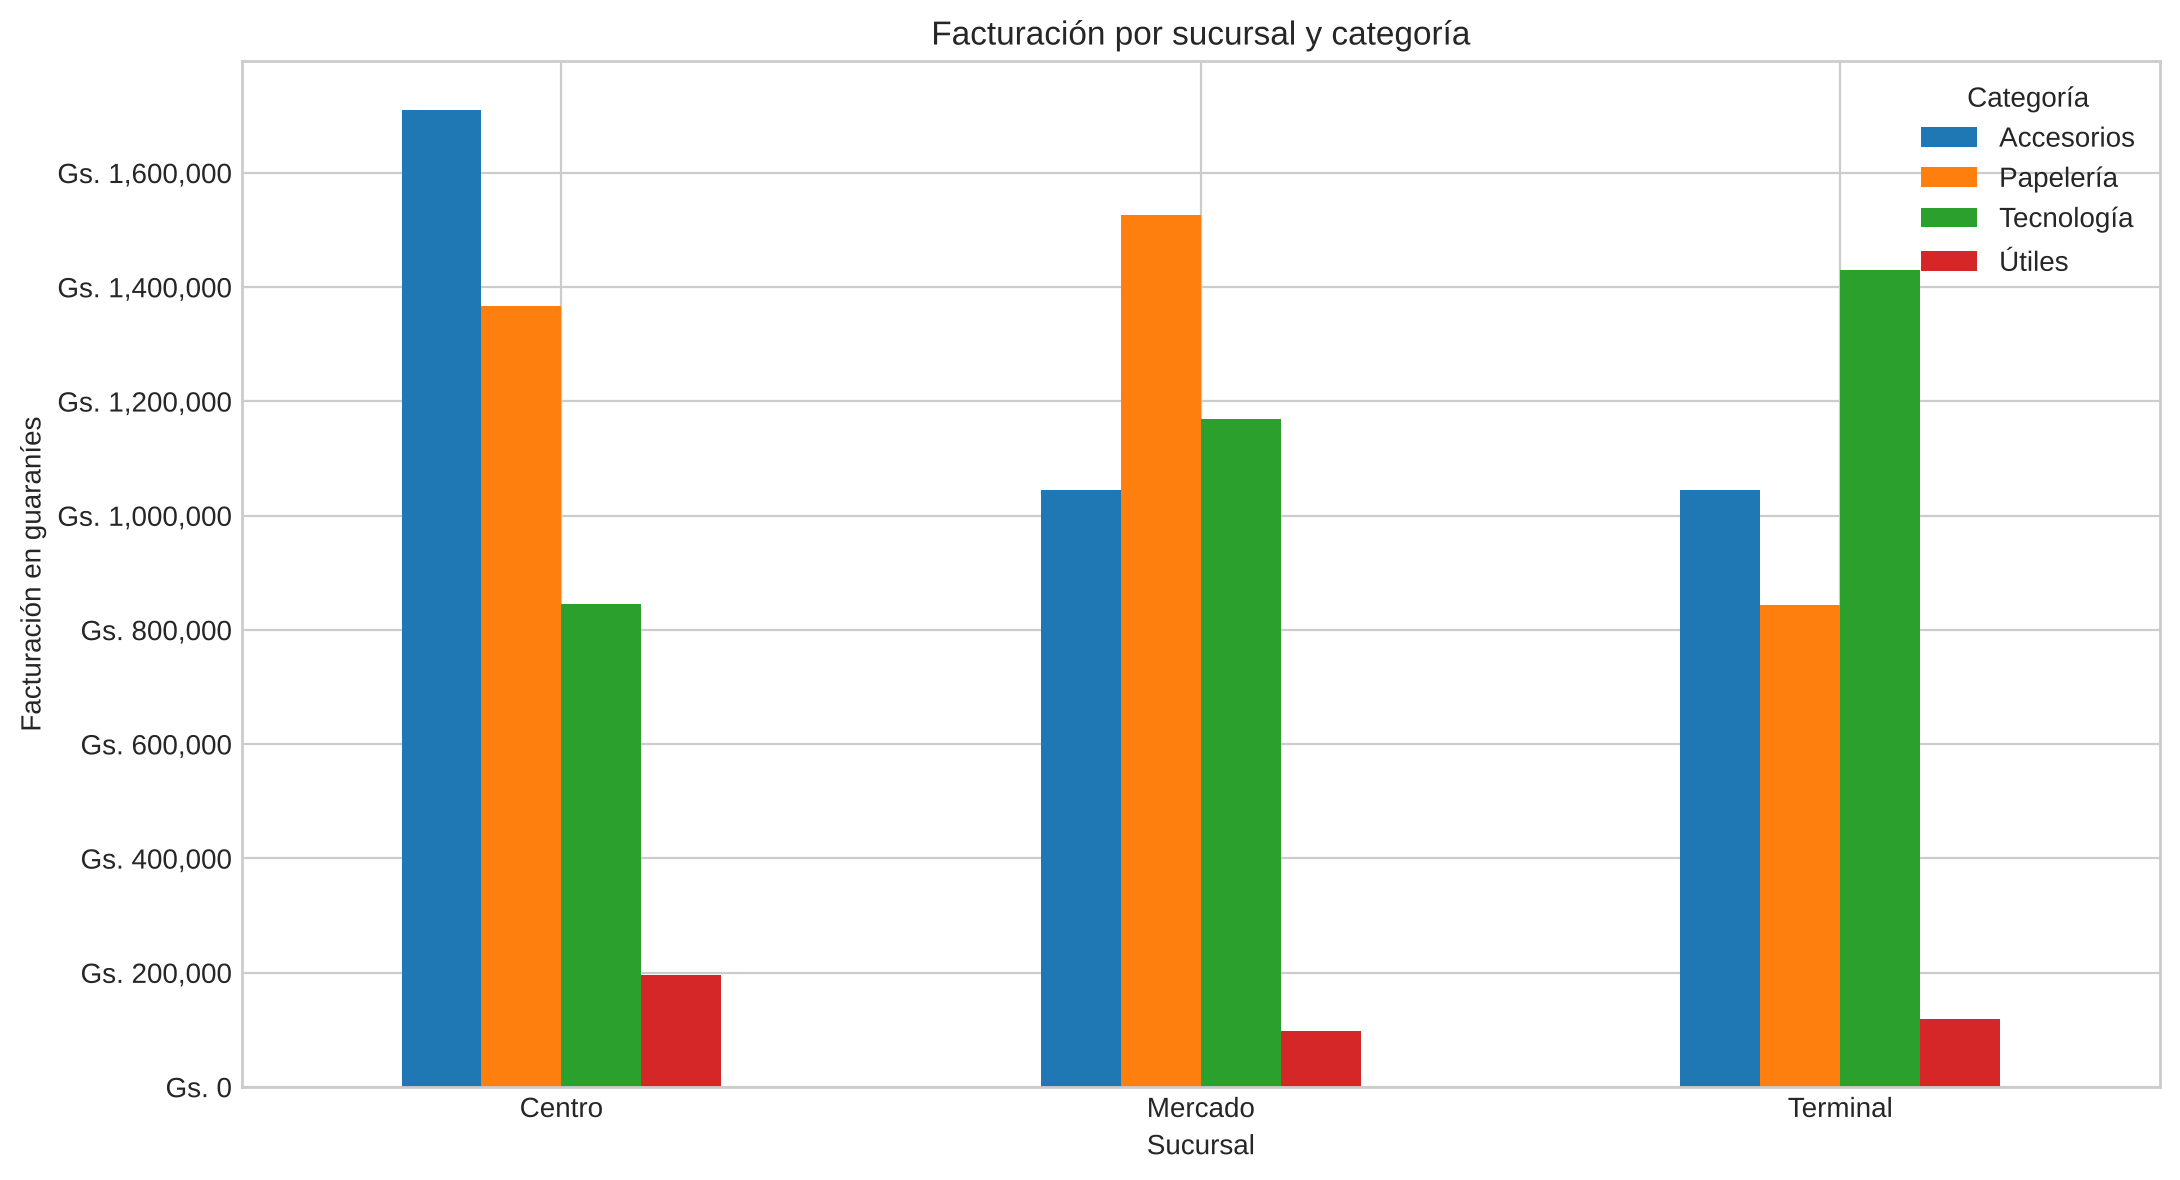

In [21]:
ax = tabla_sucursal_categoria.plot(kind='bar', figsize=(11, 6))
ax.set_title('Facturación por sucursal y categoría')
ax.set_xlabel('Sucursal')
ax.set_ylabel('Facturación en guaraníes')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Categoría')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'Gs. {x:,.0f}'))
plt.tight_layout()
plt.show()

### Ejemplo 4: gráfico circular y uso responsable

El gráfico circular funciona mejor con pocas categorías. Si hay demasiadas porciones, las comparaciones se vuelven difíciles.

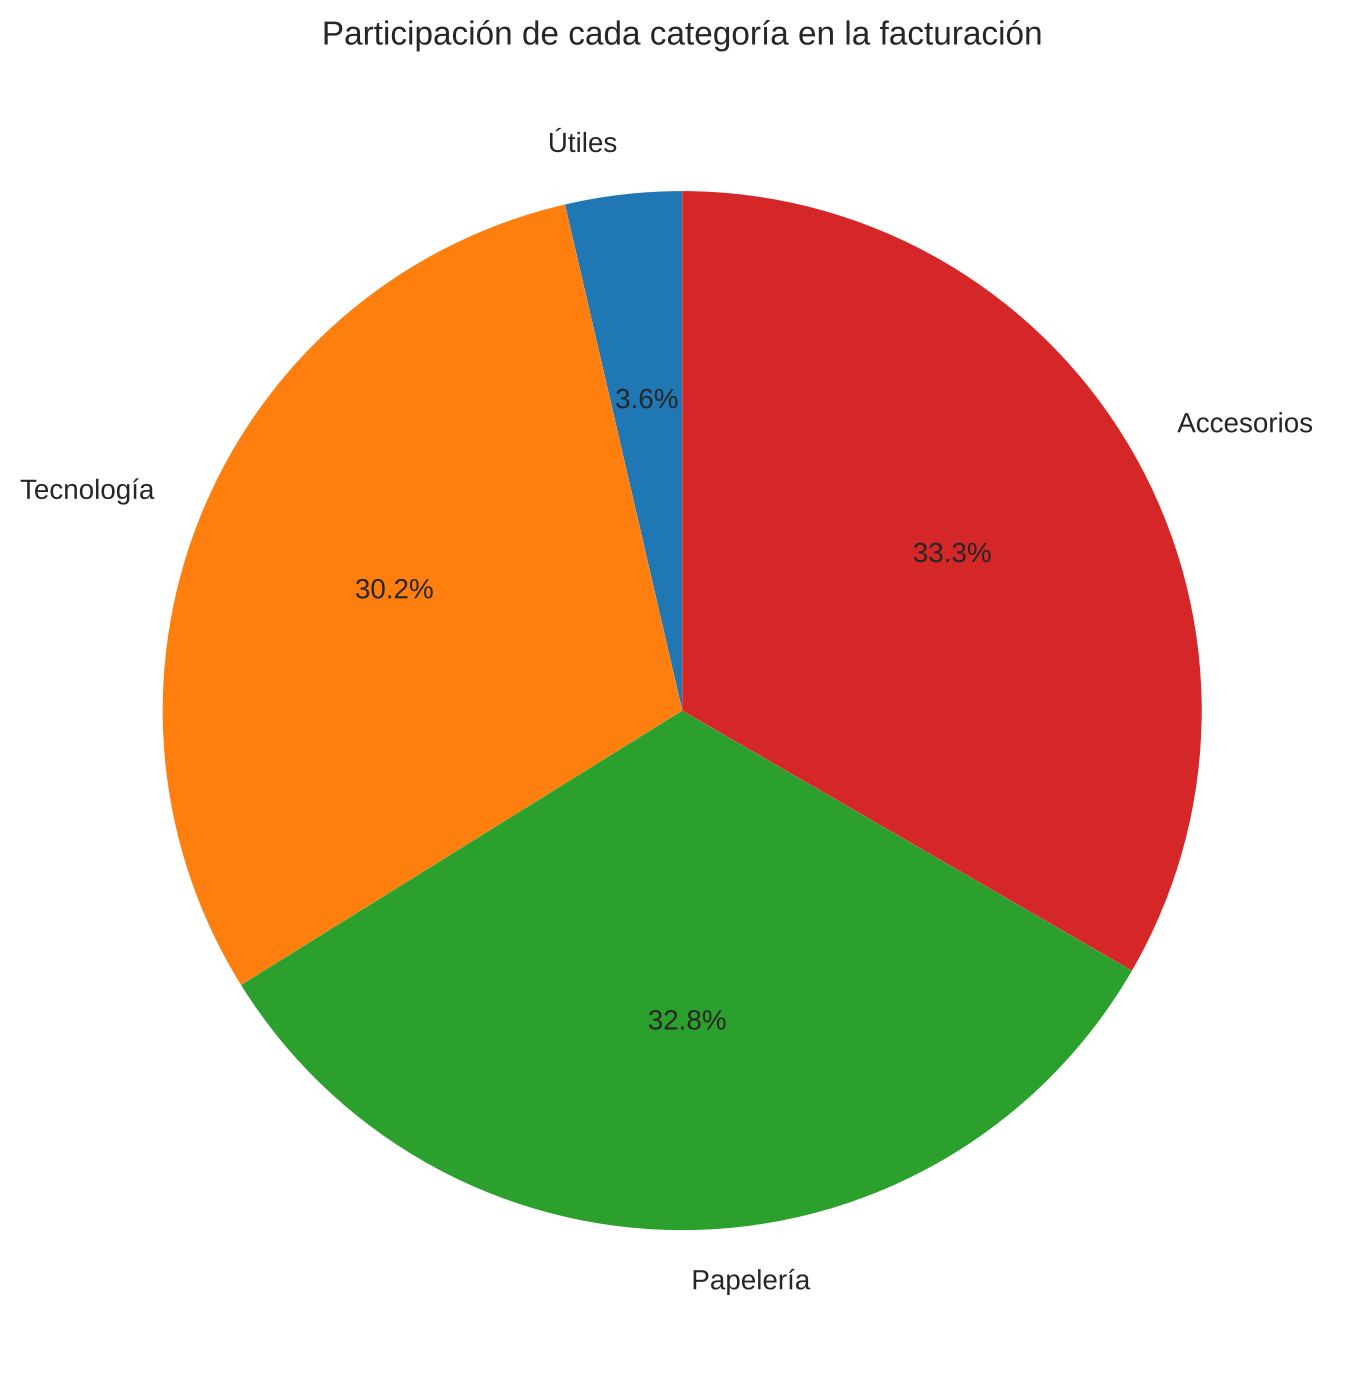

In [22]:
ventas_categoria.plot(
    kind='pie', autopct='%1.1f%%', startangle=90, figsize=(7, 7),
    ylabel='', title='Participación de cada categoría en la facturación'
)
plt.tight_layout()
plt.show()

### Errores frecuentes que debemos evitar

- usar un gráfico de líneas para categorías sin orden temporal;
- omitir títulos o unidades;
- recargar el gráfico con demasiados colores;
- utilizar un gráfico circular con demasiadas porciones;
- afirmar una causa cuando los datos solo muestran una diferencia;
- modificar la escala para exagerar cambios pequeños.

## 6. Práctica guiada 3: gráficos e interpretación 

Realice las siguientes actividades:

1. Calcule la facturación por producto y represéntela con barras horizontales.
2. Calcule la facturación mensual de cada vendedor y represéntela mediante líneas.
3. Represente las unidades vendidas por sucursal y producto con barras agrupadas.
4. Personalice títulos, nombres de ejes, colores y tamaño.
5. Debajo de cada gráfico escriba un hallazgo que incluya evidencia numérica.

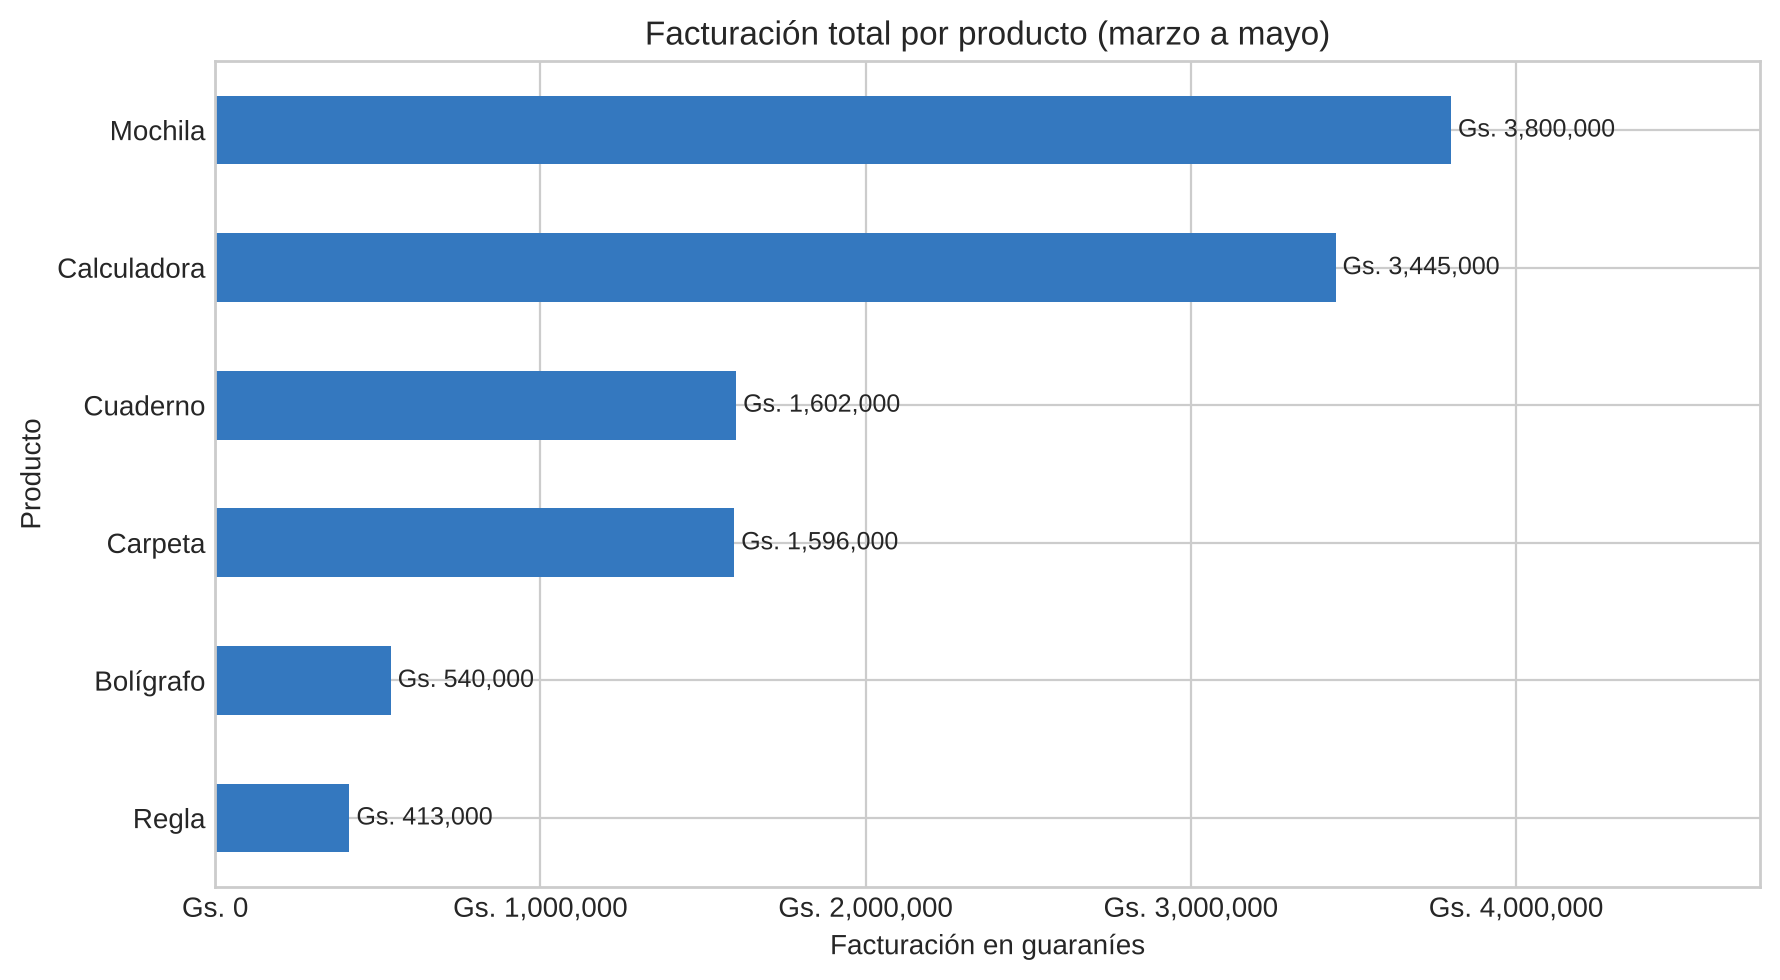

producto
Mochila        3800000
Calculadora    3445000
Cuaderno       1602000
Carpeta        1596000
Bolígrafo       540000
Regla           413000
Name: total_venta, dtype: int64

In [23]:
# Ejercicio gráfico 1: facturación por producto
ventas_producto = df_limpio.groupby("producto")["total_venta"].sum().sort_values()

ax = ventas_producto.plot(kind="barh", color="#3478BF", figsize=(9, 5))
ax.set_title("Facturación total por producto (marzo a mayo)")
ax.set_xlabel("Facturación en guaraníes")
ax.set_ylabel("Producto")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"Gs. {x:,.0f}"))
for i, valor in enumerate(ventas_producto):
    ax.text(valor, i, f" Gs. {valor:,.0f}", va="center", fontsize=9)
ax.set_xlim(0, ventas_producto.max() * 1.25)
plt.tight_layout()
plt.show()

ventas_producto.sort_values(ascending=False)

**Interpretación del gráfico 1:**  
Mochila (Gs. 3.800.000) y Calculadora (Gs. 3.445.000) son los productos que más facturan: juntos suman Gs. 7.245.000, alrededor del 64 % del total. En cambio, Bolígrafo y Regla, aunque se venden con frecuencia, aportan menos de Gs. 550.000 cada uno, por su bajo precio unitario.

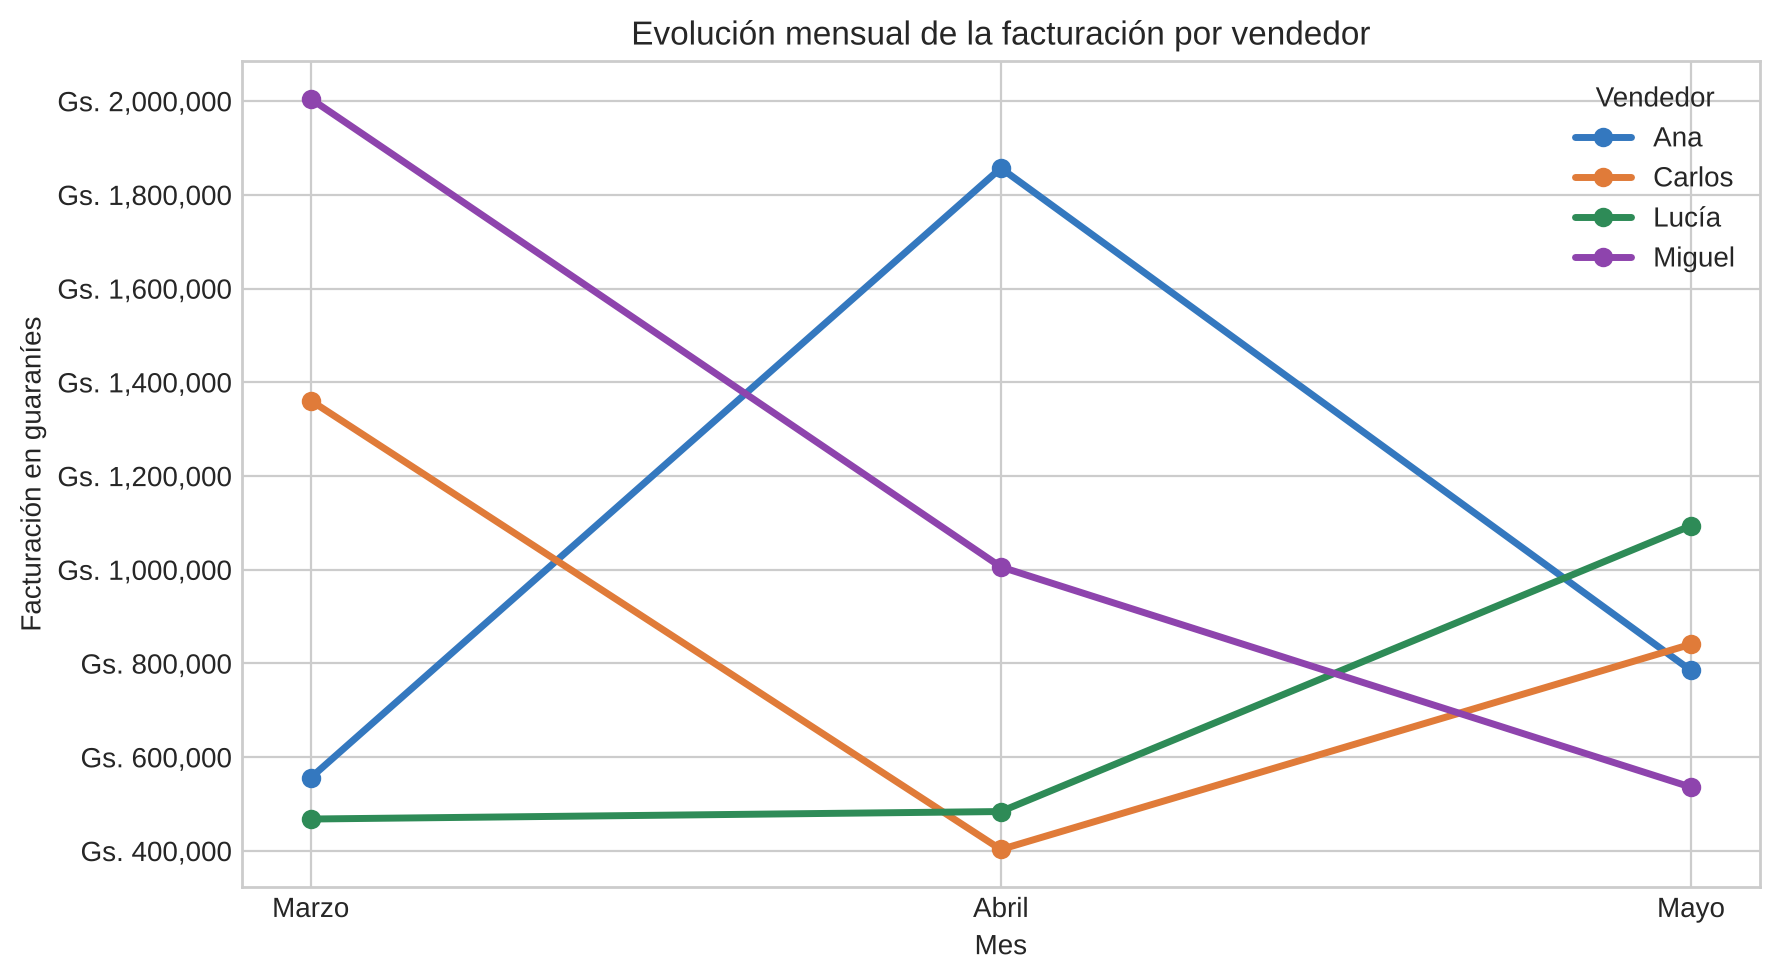

vendedor,Ana,Carlos,Lucía,Miguel
nombre_mes,,,,
Marzo,556000,1361000,468000,2005000
Abril,1857000,403000,484000,1006000
Mayo,785000,841000,1094000,536000


In [24]:
# Ejercicio gráfico 2: evolución mensual por vendedor
ventas_vendedor_mes_linea = df_limpio.pivot_table(
    index="nombre_mes",
    columns="vendedor",
    values="total_venta",
    aggfunc="sum",
    fill_value=0
).reindex(["Marzo", "Abril", "Mayo"])

ax = ventas_vendedor_mes_linea.plot(
    kind="line", marker="o", linewidth=2.5, figsize=(9, 5),
    color=["#3478BF", "#E07B39", "#2E8B57", "#8E44AD"]
)
ax.set_title("Evolución mensual de la facturación por vendedor")
ax.set_xlabel("Mes")
ax.set_ylabel("Facturación en guaraníes")
ax.set_xticks(range(3))
ax.set_xticklabels(["Marzo", "Abril", "Mayo"])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"Gs. {x:,.0f}"))
ax.legend(title="Vendedor")
plt.tight_layout()
plt.show()

ventas_vendedor_mes_linea

**Interpretación del gráfico 2:**  
Las ventas de cada vendedor varían mucho de un mes a otro. Miguel pasó de Gs. 2.005.000 en Marzo a Gs. 536.000 en Mayo (una caída de más del 70 %), mientras que Lucía fue la única que creció de forma sostenida: de Gs. 468.000 en Marzo a Gs. 1.094.000 en Mayo. Los datos muestran el cambio, pero no explican su causa.

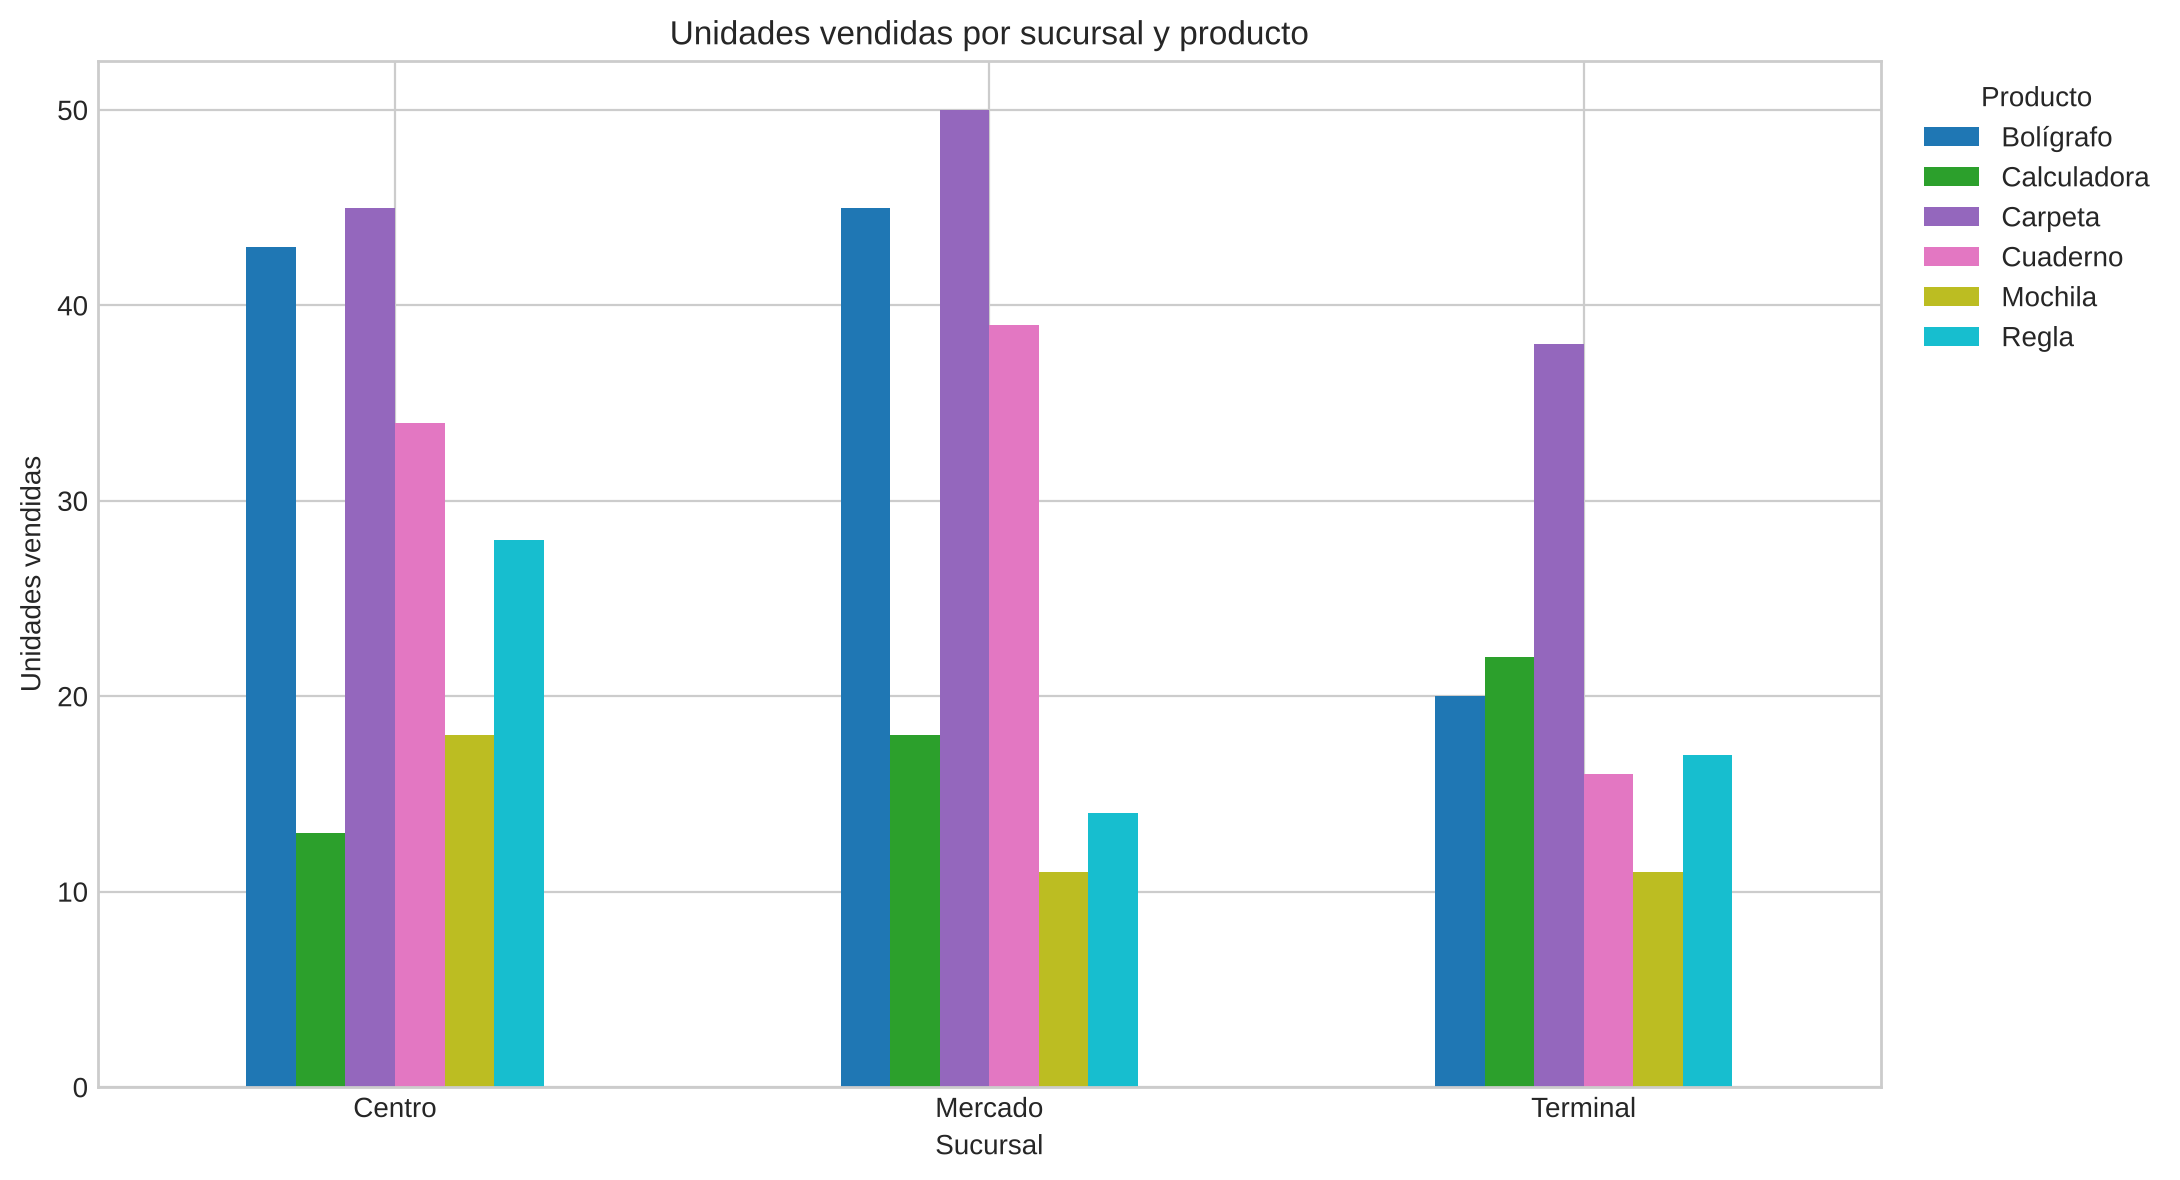

In [25]:
# Ejercicio gráfico 3: unidades por sucursal y producto
ax = unidades_sucursal_producto.plot(kind="bar", figsize=(11, 6), colormap="tab10")
ax.set_title("Unidades vendidas por sucursal y producto")
ax.set_xlabel("Sucursal")
ax.set_ylabel("Unidades vendidas")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Producto", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación del gráfico 3:**  
Carpeta es el producto con más unidades vendidas en las tres sucursales (45 en Centro, 50 en Mercado y 38 en Terminal), seguida de Bolígrafo en Centro y Mercado. Terminal vende menos unidades de papelería que las otras sucursales (por ejemplo, 20 bolígrafos frente a 45 en Mercado), pero es la que más calculadoras vende (22 unidades).

## 7. Cómo interpretar correctamente 

Una conclusión sólida contiene tres elementos:

1. **Hallazgo:** qué se observa.
2. **Evidencia:** número o comparación que lo demuestra.
3. **Implicación:** por qué puede ser importante.

### Modelo

> La categoría Tecnología presenta la mayor facturación, con Gs. X. Esto indica que, aunque no necesariamente tenga más operaciones, sus ventas aportan una parte importante de los ingresos.

Observe que no afirmamos la causa. Para decir *por qué* ocurrió necesitaríamos otros datos o una investigación adicional.

## 8. Desafío integrador: miniinforme gerencial 

La administración solicita un informe breve para orientar una campaña comercial. Prepare lo siguiente:

1. Una tabla dinámica de facturación por sucursal y categoría.
2. Una tabla de frecuencia de operaciones por vendedor y sucursal.
3. Un gráfico de barras que permita comparar productos.
4. Un gráfico de líneas que muestre la evolución mensual.
5. Tres conclusiones respaldadas por números.
6. Dos recomendaciones concretas para la librería.

### Criterios de logro

| Criterio | Puntaje |
|---|---:|
| Tablas correctas y legibles | 3 |
| Gráficos adecuados y personalizados | 3 |
| Conclusiones con evidencia | 2 |
| Recomendaciones coherentes | 2 |
| **Total** | **10** |

In [26]:
# 1. Tabla dinámica de facturación por sucursal y categoría
informe_sucursal_categoria = pd.pivot_table(
    df_limpio, values="total_venta", index="sucursal", columns="categoria",
    aggfunc="sum", fill_value=0, margins=True, margins_name="Total"
)
print("Facturación por sucursal y categoría (Gs.)")
display(informe_sucursal_categoria)

# Participación de cada categoría dentro de cada sucursal (%)
participacion = (tabla_sucursal_categoria.div(tabla_sucursal_categoria.sum(axis=1), axis=0) * 100).round(1)
print("Participación de cada categoría en la facturación de cada sucursal (%)")
display(participacion)

# 2. Tabla de frecuencia de operaciones por vendedor y sucursal
informe_frecuencia = pd.crosstab(
    df_limpio["vendedor"], df_limpio["sucursal"],
    margins=True, margins_name="Total"
)
print("Cantidad de operaciones por vendedor y sucursal")
display(informe_frecuencia)

# Operaciones frente a facturación por vendedor
resumen_vendedor = df_limpio.groupby("vendedor")["total_venta"].agg(
    operaciones="count", facturacion="sum", ticket_promedio="mean"
).sort_values("facturacion", ascending=False).round(0)
print("Operaciones, facturación y ticket promedio por vendedor")
display(resumen_vendedor)

Facturación por sucursal y categoría (Gs.)


categoria,Accesorios,Papelería,Tecnología,Útiles,Total
sucursal,,,,,
Centro,1710000,1367000,845000,196000,4118000
Mercado,1045000,1527000,1170000,98000,3840000
Terminal,1045000,844000,1430000,119000,3438000
Total,3800000,3738000,3445000,413000,11396000


Participación de cada categoría en la facturación de cada sucursal (%)


categoria,Accesorios,Papelería,Tecnología,Útiles
sucursal,,,,
Centro,41.50,33.20,20.50,4.80
Mercado,27.20,39.80,30.50,2.60
Terminal,30.40,24.50,41.60,3.50


Cantidad de operaciones por vendedor y sucursal


sucursal,Centro,Mercado,Terminal,Total
vendedor,,,,
Ana,8,12,4,24
Carlos,17,4,12,33
Lucía,12,12,7,31
Miguel,10,12,10,32
Total,47,40,33,120


Operaciones, facturación y ticket promedio por vendedor


,operaciones,facturacion,ticket_promedio
vendedor,,,
Miguel,32,3547000,"110,844.00"
Ana,24,3198000,"133,250.00"
Carlos,33,2605000,"78,939.00"
Lucía,31,2046000,"66,000.00"


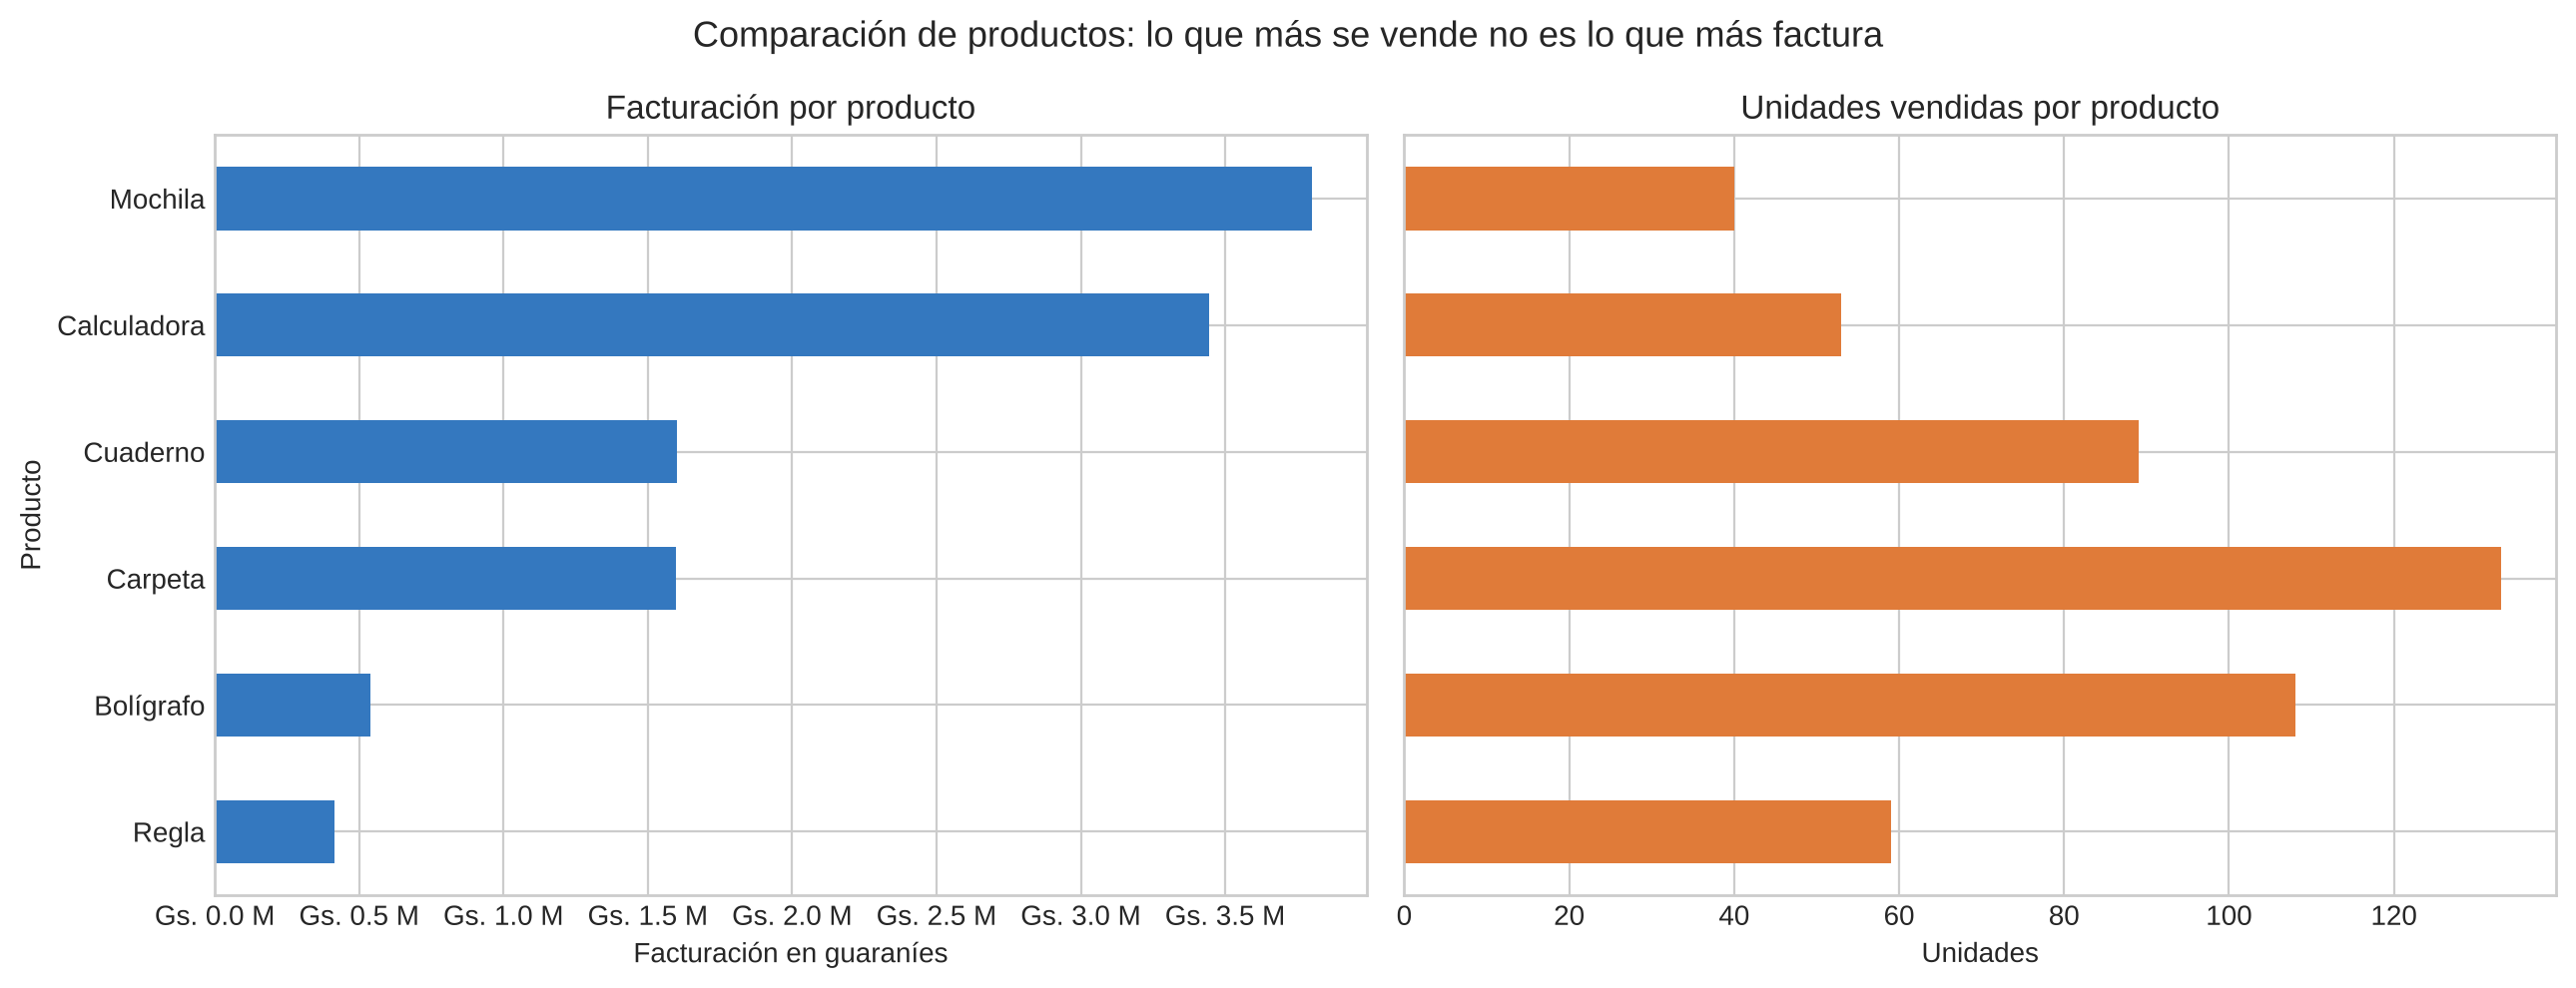

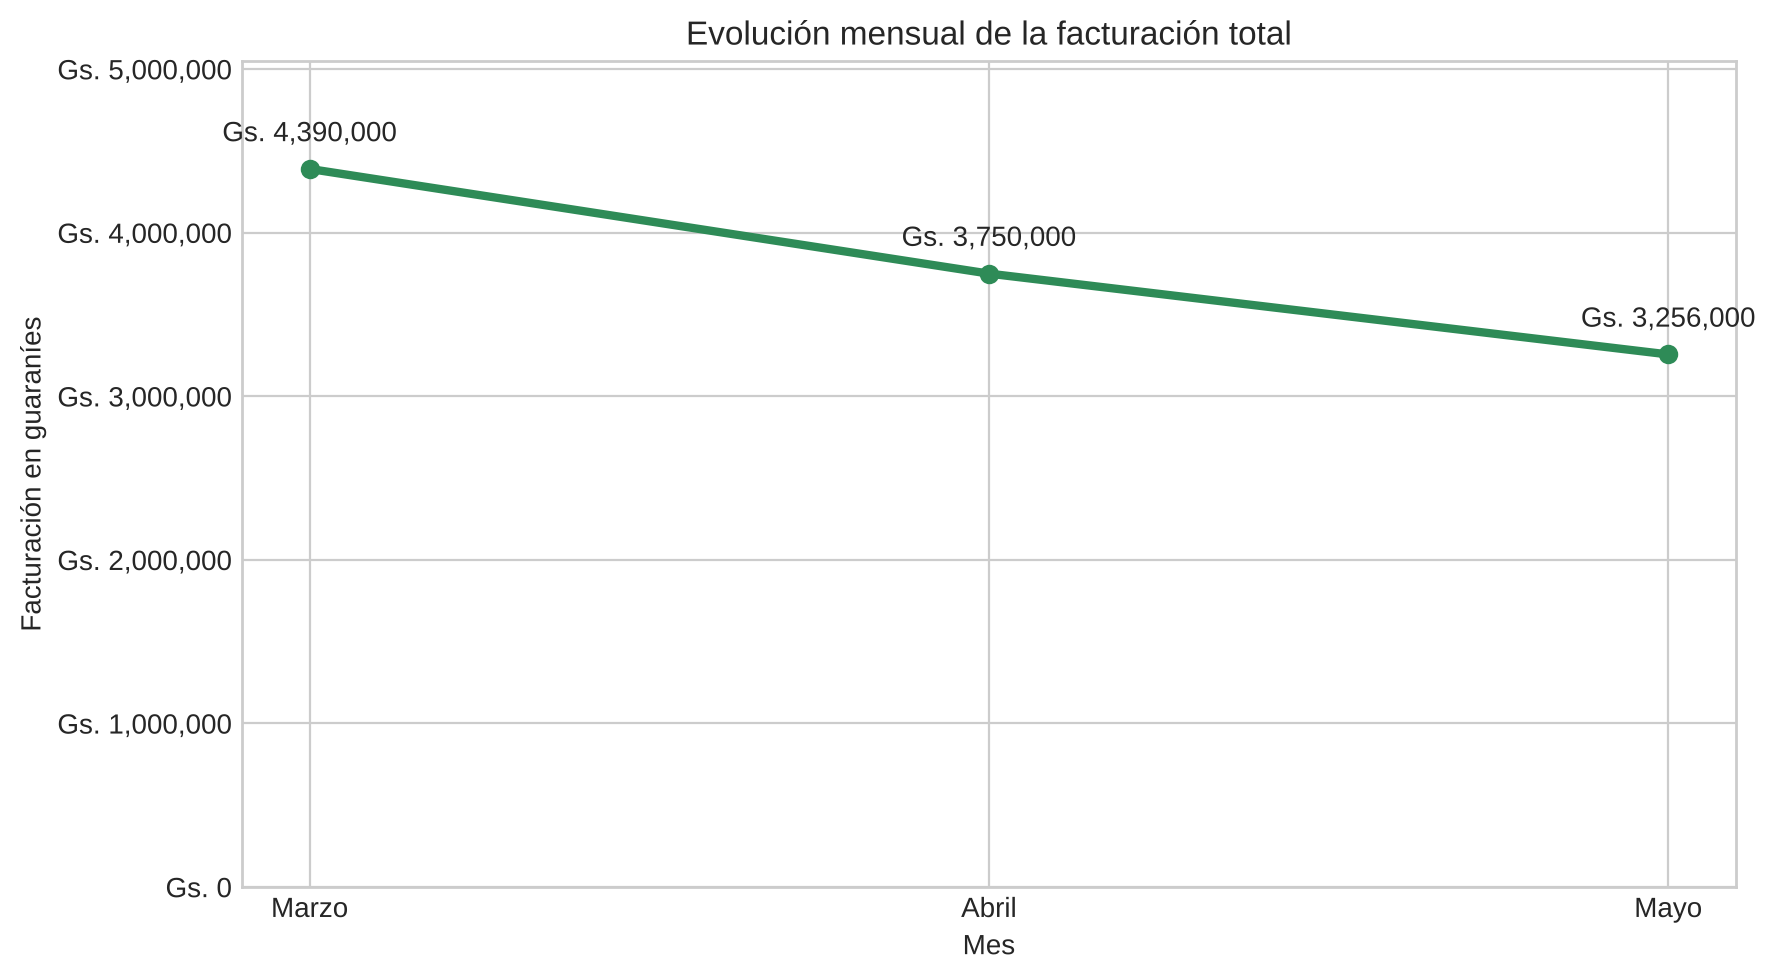

Variación porcentual respecto del mes anterior:
nombre_mes
Marzo      NaN
Abril   -14.60
Mayo    -13.20
Name: total_venta, dtype: float64
Variación Marzo → Mayo: -25.8 %


In [27]:
# 3. Gráfico de barras para comparar productos (facturación y unidades)
resumen_producto = df_limpio.groupby("producto").agg(
    facturacion=("total_venta", "sum"), unidades=("cantidad", "sum")
).sort_values("facturacion")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
resumen_producto["facturacion"].plot(kind="barh", ax=ax1, color="#3478BF")
ax1.set_title("Facturación por producto")
ax1.set_xlabel("Facturación en guaraníes")
ax1.set_ylabel("Producto")
ax1.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"Gs. {x/1e6:,.1f} M"))

resumen_producto["unidades"].plot(kind="barh", ax=ax2, color="#E07B39")
ax2.set_title("Unidades vendidas por producto")
ax2.set_xlabel("Unidades")
fig.suptitle("Comparación de productos: lo que más se vende no es lo que más factura", fontsize=13)
plt.tight_layout()
plt.show()

# 4. Gráfico de líneas con la evolución mensual
ventas_mes_informe = df_limpio.groupby("nombre_mes")["total_venta"].sum().reindex(["Marzo", "Abril", "Mayo"])
ax = ventas_mes_informe.plot(kind="line", marker="o", linewidth=3, color="#2E8B57", figsize=(9, 5))
ax.set_title("Evolución mensual de la facturación total")
ax.set_xlabel("Mes")
ax.set_ylabel("Facturación en guaraníes")
ax.set_xticks(range(3))
ax.set_xticklabels(["Marzo", "Abril", "Mayo"])
ax.set_ylim(0, ventas_mes_informe.max() * 1.15)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"Gs. {x:,.0f}"))
for i, valor in enumerate(ventas_mes_informe):
    ax.annotate(f"Gs. {valor:,.0f}", (i, valor), textcoords="offset points", xytext=(0, 10), ha="center")
plt.tight_layout()
plt.show()

variacion = (ventas_mes_informe.pct_change() * 100).round(1)
print("Variación porcentual respecto del mes anterior:")
print(variacion)
print(f"Variación Marzo → Mayo: {(ventas_mes_informe['Mayo'] / ventas_mes_informe['Marzo'] - 1) * 100:.1f} %")

### Miniinforme

**Conclusión 1:** Accesorios (Mochila) y Tecnología (Calculadora) generan la mayor parte de los ingresos con pocas operaciones. Mochila facturó Gs. 3.800.000 y Calculadora Gs. 3.445.000: juntas representan cerca del 64 % del total (Gs. 11.396.000) con solo 24 de las 120 operaciones. En cambio, Papelería registró 84 operaciones y facturó Gs. 3.738.000.

**Conclusión 2:** La facturación total disminuyó mes a mes: Gs. 4.390.000 en Marzo, Gs. 3.750.000 en Abril (−14,6 %) y Gs. 3.256.000 en Mayo (−13,2 % respecto de Abril). Entre Marzo y Mayo la caída acumulada es de aproximadamente 25,8 %. Los datos no permiten afirmar la causa.

**Conclusión 3:** Registrar más operaciones no equivale a facturar más. Carlos es quien más operaciones registró (33), pero factura Gs. 2.605.000; Miguel, con 32 operaciones, factura Gs. 3.547.000, y Ana, con solo 24, factura Gs. 3.198.000. Además, cada sucursal tiene una categoría líder distinta: Accesorios en Centro (Gs. 1.710.000, 41,5 %), Papelería en Mercado (Gs. 1.527.000, 39,8 %) y Tecnología en Terminal (Gs. 1.430.000, 41,6 %).

**Recomendación 1:** Diferenciar la campaña según la sucursal, promocionando la categoría que ya lidera en cada una: mochilas en Centro, calculadoras en Terminal y papelería (carpetas y cuadernos, los de más unidades) en Mercado. Se puede ofrecer un combo "mochila + cuaderno" o "calculadora + carpeta" para combinar un producto de alto valor con uno de alta rotación.

**Recomendación 2:** Antes de lanzar la campaña, investigar por qué la facturación cayó cerca de 26 % entre Marzo y Mayo (por ejemplo, revisando si coincide con el inicio de clases) y hacer seguimiento mensual con estas mismas tablas. En paralelo, compartir entre los vendedores las prácticas de quienes tienen mayor ticket promedio, para que las operaciones de mayor cantidad (como las de Carlos) también aumenten su valor.

## 9. Cierre y metacognición — 5 minutos

Complete las siguientes frases:

- Hoy aprendí que una tabla dinámica **permite resumir muchos registros cruzando dos categorías (filas y columnas) y aplicando una operación como suma, promedio o conteo.**
- El gráfico más útil para comparar categorías es **el gráfico de barras (horizontales si los nombres son largos), ordenado de mayor a menor.**
- Antes de formular una conclusión debo **verificar el número que la respalda y distinguir lo que se observa de la posible causa, que los datos no demuestran.**
- Una dificultad que todavía necesito practicar es **elegir entre `groupby()`, `pivot_table()` y `crosstab()` según la pregunta, y personalizar bien los ejes de Matplotlib.**

### Lista de verificación

- [x] Construí una tabla con `pivot_table()`.
- [x] Utilicé correctamente `aggfunc`.
- [x] Construí una tabla con `crosstab()`.
- [x] Elegí el gráfico según la pregunta.
- [x] Incluí título, ejes y unidades.
- [x] Redacté conclusiones con evidencia numérica.
- [x] Evité atribuir causas que los datos no demuestran.